In [7]:
import pandas as pd 


In [13]:
# Value-weighted table only: stop before the equal-weighted section further down the file
industry = pd.read_csv("data/17_Industry_Portfolios_Daily.csv", nrows=26317, index_col=0)

fama_french = pd.read_csv("data/F-F_Research_Data_Factors_daily.csv", index_col=0)
fama_french = fama_french[fama_french.index.astype(str).str.strip().str.isdigit()].astype(float)  # drop copyright footer

industry.index = pd.to_datetime(industry.index.astype(str).str.strip(), format="%Y%m%d")
fama_french.index = pd.to_datetime(fama_french.index.astype(str).str.strip(), format="%Y%m%d")

display(industry.head())
display(fama_french.head())

,Food,Mines,Oil,Clths,Durbl,Chems,Cnsum,Cnstr,Steel,FabPr,Machn,Cars,Trans,Utils,Rtail,Finan,Other
1926-07-01,0.08,0.30,0.62,0.14,-1.09,0.56,0.04,0.30,-0.62,-0.79,-0.12,-0.15,0.08,0.61,-0.01,0.58,-0.03
1926-07-02,0.10,0.36,0.71,-0.16,-0.57,1.01,0.60,-0.03,1.18,0.96,0.38,1.09,0.05,0.47,0.01,-0.16,0.38
1926-07-06,0.01,-0.19,0.17,0.37,-1.90,0.21,0.47,0.38,0.17,0.68,0.51,0.88,-0.16,0.73,-0.23,0.20,0.18
1926-07-07,0.59,-0.17,-0.03,0.18,-0.06,0.83,-0.12,-0.10,-0.03,2.36,-0.12,0.04,0.12,0.17,-0.60,-0.07,0.40
1926-07-08,1.07,0.34,0.09,0.75,-0.28,-0.14,0.42,0.35,-0.07,-0.50,0.48,0.01,0.46,-0.20,-0.36,-0.48,0.44


,Mkt-RF,SMB,HML,RF
1926-07-01,0.09,-0.23,-0.28,0.01
1926-07-02,0.45,-0.34,-0.03,0.01
1926-07-06,0.17,0.29,-0.38,0.01
1926-07-07,0.09,-0.62,0.03,0.01
1926-07-08,0.22,-0.38,0.18,0.01


In [14]:
data = industry.join(
    fama_french[["Mkt-RF", "RF"]],
    how="inner"
)
data.head()

,Food,Mines,Oil,Clths,Durbl,Chems,Cnsum,Cnstr,Steel,FabPr,Machn,Cars,Trans,Utils,Rtail,Finan,Other,Mkt-RF,RF
1926-07-01,0.08,0.30,0.62,0.14,-1.09,0.56,0.04,0.30,-0.62,-0.79,-0.12,-0.15,0.08,0.61,-0.01,0.58,-0.03,0.09,0.01
1926-07-02,0.10,0.36,0.71,-0.16,-0.57,1.01,0.60,-0.03,1.18,0.96,0.38,1.09,0.05,0.47,0.01,-0.16,0.38,0.45,0.01
1926-07-06,0.01,-0.19,0.17,0.37,-1.90,0.21,0.47,0.38,0.17,0.68,0.51,0.88,-0.16,0.73,-0.23,0.20,0.18,0.17,0.01
1926-07-07,0.59,-0.17,-0.03,0.18,-0.06,0.83,-0.12,-0.10,-0.03,2.36,-0.12,0.04,0.12,0.17,-0.60,-0.07,0.40,0.09,0.01
1926-07-08,1.07,0.34,0.09,0.75,-0.28,-0.14,0.42,0.35,-0.07,-0.50,0.48,0.01,0.46,-0.20,-0.36,-0.48,0.44,0.22,0.01


In [55]:
data = data.loc["2010-01-01":"2024-12-31"].copy()
data.head()
print (data.index.min(), data.index.max()) # chose 15 years 

2010-01-04 00:00:00 2024-12-31 00:00:00


In [19]:
excess_returns = data[industry.columns].sub(data["RF"], axis=0)
excess_returns.head()

,Food,Mines,Oil,Clths,Durbl,Chems,Cnsum,Cnstr,Steel,FabPr,Machn,Cars,Trans,Utils,Rtail,Finan,Other
2010-01-04,0.70,4.27,2.89,0.42,1.71,3.14,1.39,0.94,3.75,1.72,1.91,1.90,1.70,0.66,0.87,2.14,1.47
2010-01-05,0.47,1.36,0.68,1.20,-0.15,0.82,-0.69,0.19,-0.30,-0.06,0.18,2.49,0.93,-0.84,-0.17,1.04,0.12
2010-01-06,0.13,3.18,0.86,0.44,0.12,1.18,0.15,0.31,3.82,0.49,-0.30,1.16,-0.18,0.54,-0.01,0.23,-0.37
2010-01-07,-0.25,-0.94,-0.32,0.68,1.18,0.20,-0.18,2.39,-0.35,0.55,0.05,1.31,0.27,-0.45,0.62,2.09,0.19
2010-01-08,-0.61,1.84,0.42,0.14,0.18,0.38,-0.06,0.01,3.06,1.10,1.05,0.33,1.31,-0.05,-0.03,-0.21,0.43


In [28]:
import statsmodels.api as stats

betas = {}
for industry_col in industry.columns:
    Y = excess_returns[industry_col]
    X = data[["Mkt-RF"]]
    X = stats.add_constant(X)
    model = stats.OLS(Y, X).fit()
    betas[industry_col] = float(model.params["Mkt-RF"])
for industry_col, beta in betas.items():
    print(f"{industry_col}: {round(beta, 4)}")


Food: 0.6015
Mines: 1.1089
Oil: 1.065
Clths: 1.0913
Durbl: 1.0789
Chems: 1.102
Cnsum: 0.6344
Cnstr: 1.0661
Steel: 1.3511
FabPr: 1.0721
Machn: 1.1971
Cars: 1.2754
Trans: 1.0232
Utils: 0.6457
Rtail: 0.8643
Finan: 1.1126
Other: 1.0212


I tested our different MUs, but opted for 0 as the data was evenly divided and it made more economic sense for the final interpretation

In [46]:
mu = 0
(data["Mkt-RF"] >= mu).sum(), (data["Mkt-RF"] < mu).sum()

(np.int64(2077), np.int64(1697))

In [47]:
beta_up = {}
beta_down = {}

updays = data["Mkt-RF"] >= mu
downdays = data["Mkt-RF"] < mu

for industry_col in industry.columns:
    Y = excess_returns.loc[updays, industry_col]
    X = data.loc[updays, "Mkt-RF"]
    X = stats.add_constant(X)
    model = stats.OLS(Y, X).fit()
    beta_up [industry_col] = float(model.params["Mkt-RF"])
    Y = excess_returns.loc[downdays, industry_col]
    X = data.loc[downdays, "Mkt-RF"]
    X = stats.add_constant(X)
    model = stats.OLS(Y, X).fit()
    beta_down[industry_col] = float(model.params["Mkt-RF"])

print("Upside Betas")
for industry_col, beta in beta_up.items():
    print(f"{industry_col}: {round(beta,4)}")

print("Downside Betas")

for industry_col, beta in beta_down.items():
    print(f"{industry_col}: {round(beta, 4)}")


Upside Betas
Food: 0.6312
Mines: 1.0644
Oil: 1.0514
Clths: 1.0875
Durbl: 1.0179
Chems: 1.1023
Cnsum: 0.6798
Cnstr: 1.0356
Steel: 1.2815
FabPr: 1.0768
Machn: 1.2084
Cars: 1.1472
Trans: 1.0021
Utils: 0.7475
Rtail: 0.8296
Finan: 1.1485
Other: 1.0164
Downside Betas
Food: 0.6562
Mines: 0.997
Oil: 1.1096
Clths: 1.1165
Durbl: 1.0337
Chems: 1.0757
Cnsum: 0.6484
Cnstr: 1.0886
Steel: 1.2756
FabPr: 1.04
Machn: 1.1371
Cars: 1.2811
Trans: 1.0612
Utils: 0.6947
Rtail: 0.8741
Finan: 1.1304
Other: 1.017


In [48]:
avg_returns = data[industry.columns].mean()
results = pd.DataFrame({
    "Avg_Return": avg_returns,
    "Beta": pd.Series(betas),
    "Beta_Up": pd.Series(beta_up),
    "Beta_Down": pd.Series(beta_down)
})

results.round(4)

,Avg_Return,Beta,Beta_Up,Beta_Down
Food,0.0393,0.6015,0.6312,0.6562
Mines,0.0317,1.1089,1.0644,0.9970
Oil,0.0392,1.0650,1.0514,1.1096
Clths,0.0534,1.0913,1.0875,1.1165
Durbl,0.0387,1.0789,1.0179,1.0337
Chems,0.0428,1.1020,1.1023,1.0757
Cnsum,0.0507,0.6344,0.6798,0.6484
Cnstr,0.0757,1.0661,1.0356,1.0886
Steel,0.0434,1.3511,1.2815,1.2756
FabPr,0.0702,1.0721,1.0768,1.0400


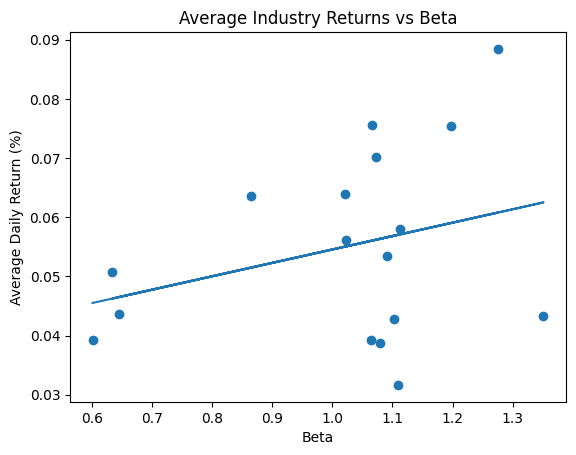

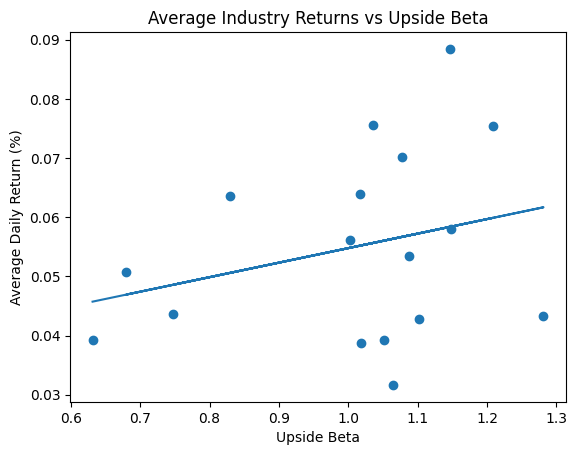

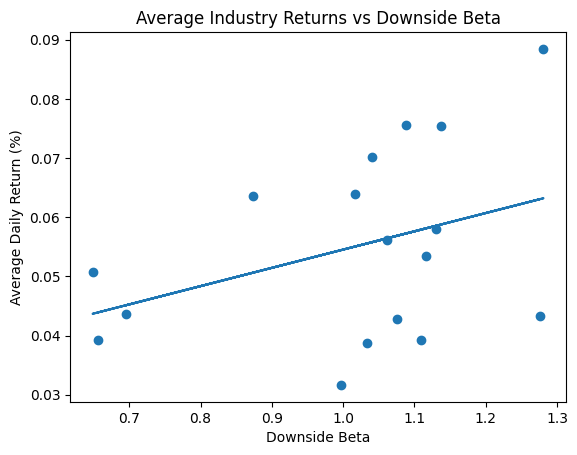

In [51]:
import matplotlib.pyplot as plt
import numpy as np

x = results["Beta"]
y = results["Avg_Return"]

# Find best-fit line: y = mx + b
m, b = np.polyfit(x, y, 1)

plt.scatter(x, y)
plt.plot(x, m*x + b)

plt.xlabel("Beta")
plt.ylabel("Average Daily Return (%)")
plt.title("Average Industry Returns vs Beta")

plt.show()

# Upside Beta
x = results["Beta_Up"]
y = results["Avg_Return"]
m, b = np.polyfit(x, y, 1)
plt.scatter(x, y)
plt.plot(x, m*x + b)
plt.xlabel("Upside Beta")
plt.ylabel("Average Daily Return (%)")
plt.title("Average Industry Returns vs Upside Beta")
plt.show()

# Downside Beta
x = results["Beta_Down"]
y = results["Avg_Return"]
m, b = np.polyfit(x, y, 1)
plt.scatter(x, y)
plt.plot(x, m*x + b)
plt.xlabel("Downside Beta")
plt.ylabel("Average Daily Return (%)")
plt.title("Average Industry Returns vs Downside Beta")
plt.show()

to understand which one works best, I can look at the plot but also want to check R^2 

In [54]:
fit_stats = {}
for beta_type in ["Beta", "Beta_Up", "Beta_Down"]:
    model = stats.OLS(results["Avg_Return"], stats.add_constant(results[beta_type])).fit()
    fit_stats[beta_type] = {"slope": model.params[beta_type], "p_value": model.pvalues[beta_type], "R2": model.rsquared}
pd.DataFrame(fit_stats).T.round(4)


,slope,p_value,R2
Beta,0.0227,0.2367,0.0920
Beta_Up,0.0245,0.2785,0.0777
Beta_Down,0.0309,0.1454,0.1359


All three slopes are positive: industries with higher betas earned higher average returns over 2010–2024. Downside beta fits best (R² = 0.136, compared with 0.092 for β and 0.078 for β⁺). This matches the downside-risk idea investors care most about how an asset does when the market falls, so they demand a higher premium for exposure on down days. However, with only 17 portfolios, all the R² values are low and none of the slopes is significant at 10%. So β⁻ explains returns slightly better, but no version of beta explains much of the variation across industries.